<a href="https://colab.research.google.com/github/ixrlts/data-analytics-case-studies/blob/main/projects/diamonds/02_price_by_cut.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('diamonds')
df.head(10)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


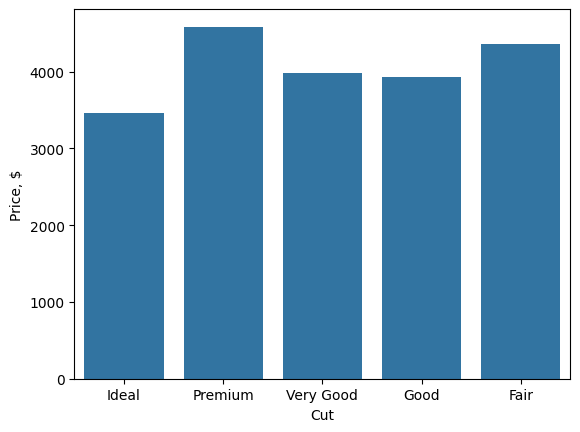

In [18]:
avg_by_cut = df.groupby('cut', observed=True)['price'].mean().reset_index().copy()
sns.barplot(data=avg_by_cut, x='cut', y='price')
plt.xlabel('Cut')
plt.ylabel('Price, $')
plt.show()

In [12]:
df.groupby('cut', observed=True).agg(
    avg_price=('price', 'mean'),
    avg_carat=('carat', 'mean')
).round(2)

,avg_price,avg_carat
cut,,
Ideal,3457.54,0.70
Premium,4584.26,0.89
Very Good,3981.76,0.81
Good,3928.86,0.85
Fair,4358.76,1.05


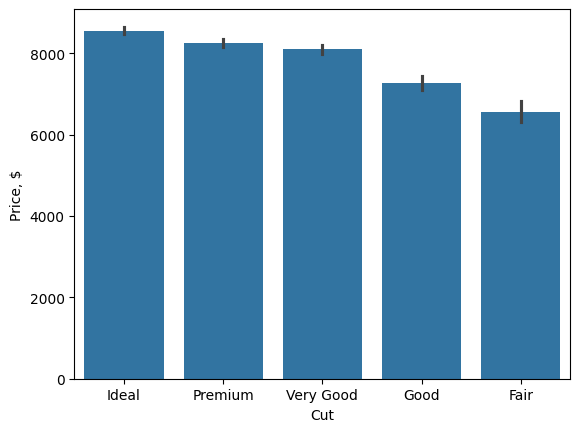

In [19]:
one_carat = df[df['carat'] >= 1]
one_carat.groupby('cut', observed=True).agg(
    avg_price=('price', 'mean')).round(2).reset_index()
sns.barplot(data=one_carat, x='cut', y='price')
plt.xlabel('Cut')
plt.ylabel('Price, $')
plt.show()

Average price for Ideal-cut diamonds (3,548 USD) is lower than other cuts, because Ideal-cut diamonds weigh less on average (0.70 carat for Ideal vs 1.05 for Fair). When comparing only diamonds of 1 carat or more, the order reverses and Ideal becomes the most expensive cut (8,563 USD), while Fair  becomes the cheapest (6,559 USD).